<a href="https://colab.research.google.com/github/OshankKarn/DNNAssignment2/blob/main/Problem1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!nvidia-smi

Sat Nov 14 06:38:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))


True
Tesla T4


# DNN Assignment 2 - Problem 1: RNN, LSTM and GRU
**Tasks 1-2 (this notebook part):** data pipelines and cells from scratch.

Student ID: `<fill in>`  |  last digit: **7 (odd)** -> task 5(c) ablation is **LSTM forget-gate bias 0 vs 1 at T = 200**

In [4]:
import os, random, time, zipfile, urllib.request, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn

os.makedirs('figures', exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', DEVICE, '| torch', torch.__version__)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
SEEDS = [0, 1, 2]

device: cuda | torch 2.14.1+cu130


## Task 1 - Data pipelines
### 1a. UCI HAR

In [5]:
import os
import urllib.request
import zipfile

# Download once (relative path, no Drive paths). The archive may contain a second zip.
if not os.path.isdir('har/UCI HAR Dataset'):
    url = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
    urllib.request.urlretrieve(url, 'har.zip')
    zipfile.ZipFile('har.zip').extractall('har')
    inner = 'har/UCI HAR Dataset.zip'
    if os.path.exists(inner):
        zipfile.ZipFile(inner).extractall('har')
ROOT = 'har/UCI HAR Dataset'
assert os.path.isdir(ROOT), os.listdir('har')
print("=== Data Extraction Successfully Verified ===")
print(f"Dataset Root Path: {os.path.abspath(ROOT)}")

=== Data Extraction Successfully Verified ===
Dataset Root Path: /content/har/UCI HAR Dataset


In [6]:
# Fixed channel order from the assignment.
CHANNELS = ['body_acc_x','body_acc_y','body_acc_z','body_gyro_x','body_gyro_y','body_gyro_z',
            'total_acc_x','total_acc_y','total_acc_z']
CLASSES = ['walking','walking_up','walking_down','sitting','standing','laying']

def load_split(split):
    # each file: (N, 128); stack channels on the last axis -> X: (N, 128, 9)
    cols = [pd.read_csv(f'{ROOT}/{split}/Inertial Signals/{c}_{split}.txt', sep=r'\s+', header=None).values
            for c in CHANNELS]
    X = np.stack(cols, axis=-1).astype(np.float32)
    y = np.loadtxt(f'{ROOT}/{split}/y_{split}.txt', dtype=int) - 1      # labels 0..5
    s = np.loadtxt(f'{ROOT}/{split}/subject_{split}.txt', dtype=int)
    return X, y, s

Xtr_all, ytr_all, str_all = load_split('train')
Xte, yte, ste = load_split('test')
print(Xtr_all.shape, Xte.shape)
assert Xtr_all.shape == (7352, 128, 9) and Xte.shape == (2947, 128, 9)
assert len(set(str_all) & set(ste)) == 0          # subjects do not overlap

(7352, 128, 9) (2947, 128, 9)


In [7]:
print(f"Training set - Rows (Samples): {Xtr_all.shape[0]}, Timesteps: {Xtr_all.shape[1]}, Features (Channels): {Xtr_all.shape[2]}")
print(f"Testing set  - Rows (Samples): {Xte.shape[0]}, Timesteps: {Xte.shape[1]}, Features (Channels): {Xte.shape[2]}")

Training set - Rows (Samples): 7352, Timesteps: 128, Features (Channels): 9
Testing set  - Rows (Samples): 2947, Timesteps: 128, Features (Channels): 9


In [8]:
def make_har(seed):
    # Subject-wise validation split: hold out 4 of the 21 training subjects.
    rng = np.random.default_rng(seed)
    subjects = np.unique(str_all)
    val_sub = rng.choice(subjects, 4, replace=False)
    is_val = np.isin(str_all, val_sub)
    Xtr, ytr = Xtr_all[~is_val], ytr_all[~is_val]
    Xva, yva = Xtr_all[is_val],  ytr_all[is_val]
    # Per-channel mean/std from the TRAINING part only (over windows and time).
    mu  = Xtr.mean(axis=(0, 1), keepdims=True)       # (1, 1, 9)
    std = Xtr.std(axis=(0, 1), keepdims=True) + 1e-8
    f = lambda X: torch.tensor((X - mu) / std)
    out = dict(Xtr=f(Xtr), ytr=torch.tensor(ytr), Xva=f(Xva), yva=torch.tensor(yva),
               Xte=f(Xte), yte=torch.tensor(yte), val_subjects=val_sub)
    return out

d = make_har(0)
print('val subjects:', d['val_subjects'], {k: tuple(v.shape) for k, v in d.items() if k != 'val_subjects'})
# tests: no subject leakage, train stats ~ N(0,1)
assert abs(d['Xtr'].mean().item()) < 1e-3 and abs(d['Xtr'].std().item() - 1) < 0.05
assert len(d['Xtr']) + len(d['Xva']) == 7352

val subjects: [ 8 17 25 21] {'Xtr': (5886, 128, 9), 'ytr': (5886,), 'Xva': (1466, 128, 9), 'yva': (1466,), 'Xte': (2947, 128, 9), 'yte': (2947,)}


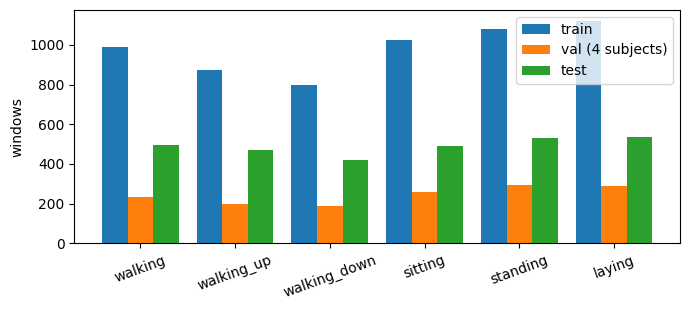

In [9]:
# Class-balance plot (train / val / test) for seed 0
cnt = lambda y: np.bincount(np.asarray(y), minlength=6)
w = 0.27; xs = np.arange(6)
plt.figure(figsize=(7, 3.2))
plt.bar(xs - w, cnt(d['ytr']), w, label='train')
plt.bar(xs,     cnt(d['yva']), w, label='val (4 subjects)')
plt.bar(xs + w, cnt(d['yte']), w, label='test')
plt.xticks(xs, CLASSES, rotation=20); plt.ylabel('windows'); plt.legend(); plt.tight_layout()
plt.savefig('figures/class_balance.png', dpi=150); plt.show()

### 1b. Adding problem

In [10]:
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)

def test_adding(T):
    for seed in (0, 1, 2):
        x, y = make_adding(1000, T, seed)
        m = x[:, :, 1]
        assert (m.sum(1) == 2).all()                         # exactly two markers
        assert (m[:, :T // 2].sum(1) == 1).all()             # one in first half
        assert (m[:, T // 2:].sum(1) == 1).all()             # one in second half
        assert np.allclose(y, (x[:, :, 0] * m).sum(1), atol=1e-6)   # target = sum of marked values
    # constant-1.0 baseline MSE should be about 0.167
    x, y = make_adding(10000, T, 0)
    print(f'T={T}: baseline MSE(1.0) = {np.mean((y - 1.0) ** 2):.4f}')

for T in (50, 100, 200, 400):
    test_adding(T)
print('adding-problem tests passed')

T=50: baseline MSE(1.0) = 0.1663
T=100: baseline MSE(1.0) = 0.1670
T=200: baseline MSE(1.0) = 0.1684
T=400: baseline MSE(1.0) = 0.1691
adding-problem tests passed


## Task 2 - Cells from scratch
Equations (x_t: (B, d), h_{t-1}: (B, h)); PyTorch gate order is kept so weights can be copied.

* RNN: $h_t=\tanh(W_{ih}x_t+b_{ih}+W_{hh}h_{t-1}+b_{hh})$
* LSTM: $[i,f,g,o]=W_{ih}x_t+b_{ih}+W_{hh}h_{t-1}+b_{hh}$; $c_t=\sigma(f)\,c_{t-1}+\sigma(i)\tanh(g)$; $h_t=\sigma(o)\tanh(c_t)$
* GRU: $r=\sigma(\cdot)$, $z=\sigma(\cdot)$, $n=\tanh(W_{in}x+b_{in}+r\odot(W_{hn}h+b_{hn}))$; $h_t=(1-z)\odot n+z\odot h_{t-1}$

`two_bias=True` mimics PyTorch (b_ih and b_hh); `two_bias=False` is the textbook one-bias form used for the by-hand counts.

In [11]:
class _Cell(nn.Module):
    G = 1                                   # number of gate blocks
    def __init__(self, d, h, two_bias=True):
        super().__init__()
        self.d, self.h, self.two_bias = d, h, two_bias
        k = 1 / math.sqrt(h)
        u = lambda *s: nn.Parameter(torch.empty(*s).uniform_(-k, k))
        self.W_ih = u(self.G * h, d)        # (G*h, d)
        self.W_hh = u(self.G * h, h)        # (G*h, h)
        self.b_ih = u(self.G * h)
        self.b_hh = u(self.G * h) if two_bias else None
    def _gates(self, x, h):
        # x: (B, d), h: (B, h) -> gi, gh: (B, G*h)
        gi = x @ self.W_ih.T + self.b_ih
        gh = h @ self.W_hh.T
        if self.two_bias:
            gh = gh + self.b_hh
        return gi, gh
    def init_state(self, B, device=None):
        return torch.zeros(B, self.h, device=device, dtype=self.W_ih.dtype)

class MyRNNCell(_Cell):
    G = 1
    def forward(self, x, h):
        gi, gh = self._gates(x, h)
        h = torch.tanh(gi + gh)
        return h, h                          # (output, new_state)

class MyLSTMCell(_Cell):
    G = 4
    def init_state(self, B, device=None):
        z = torch.zeros(B, self.h, device=device, dtype=self.W_ih.dtype); return (z, z.clone())
    def forward(self, x, state):
        h, c = state                          # each (B, h)
        gi, gh = self._gates(x, h)
        i, f, g, o = (gi + gh).chunk(4, dim=-1)       # each (B, h)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)   # (B, h)
        h = torch.sigmoid(o) * torch.tanh(c)                          # (B, h)
        return h, (h, c)

class MyGRUCell(_Cell):
    G = 3
    def forward(self, x, h):
        gi, gh = self._gates(x, h)
        ri, zi, ni = gi.chunk(3, dim=-1)
        rh, zh, nh = gh.chunk(3, dim=-1)
        r = torch.sigmoid(ri + rh); z = torch.sigmoid(zi + zh)
        n = torch.tanh(ni + r * nh)           # reset gate multiplies the hidden-side term
        h = (1 - z) * n + z * h
        return h, h

class MySeq(nn.Module):
    # Unrolls a cell over time. x: (B, T, d) -> outputs (B, T, h), final state
    def __init__(self, cell):
        super().__init__(); self.cell = cell
    def forward(self, x, state=None):
        B, T, _ = x.shape
        if state is None: state = self.cell.init_state(B, x.device)
        outs = []
        for t in range(T):
            o, state = self.cell(x[:, t], state)
            outs.append(o)
        return torch.stack(outs, dim=1), state

In [12]:
# Weight copy + equivalence test (float64 so the 1e-5 tolerance is a clean test of the maths)
def copy_weights(mine, lib, bias='both'):
    with torch.no_grad():
        mine.cell.W_ih.copy_(lib.weight_ih_l0); mine.cell.W_hh.copy_(lib.weight_hh_l0)
        mine.cell.b_ih.copy_(lib.bias_ih_l0)
        if mine.cell.two_bias: mine.cell.b_hh.copy_(lib.bias_hh_l0)

KINDS = {'RNN': (MyRNNCell, lambda d, h: nn.RNN(d, h, batch_first=True, nonlinearity='tanh')),
         'LSTM': (MyLSTMCell, lambda d, h: nn.LSTM(d, h, batch_first=True)),
         'GRU': (MyGRUCell, lambda d, h: nn.GRU(d, h, batch_first=True))}

d_in, h_dim = 9, 64
set_seed(0)
x = torch.randn(16, 40, d_in, dtype=torch.float64)
for name, (Cell, mk) in KINDS.items():
    for two_bias in (True, False):
        lib = mk(d_in, h_dim).double()
        if not two_bias:                       # one-bias form <=> library with b_hh = 0
            with torch.no_grad(): lib.bias_hh_l0.zero_()
        mine = MySeq(Cell(d_in, h_dim, two_bias)).double()
        copy_weights(mine, lib)
        out_lib, _ = lib(x); out_me, _ = mine(x)
        err = (out_lib - out_me).abs().max().item()
        assert err < 1e-5, (name, two_bias, err)
        print(f'{name:5s} two_bias={two_bias!s:5s} max |diff| = {err:.2e}')

RNN   two_bias=True  max |diff| = 0.00e+00
RNN   two_bias=False max |diff| = 0.00e+00
LSTM  two_bias=True  max |diff| = 0.00e+00
LSTM  two_bias=False max |diff| = 0.00e+00
GRU   two_bias=True  max |diff| = 1.67e-16
GRU   two_bias=False max |diff| = 1.67e-16


In [13]:
# sanity: the test must FAIL if the weights differ
lib = KINDS['LSTM'][1](9, 64).double()
mine = MySeq(MyLSTMCell(9, 64)).double()          # not copied -> different random weights
print((lib(x)[0] - mine(x)[0]).abs().max().item())   # should be clearly > 1e-2

0.558197095035275


In [14]:
# Parameter counts: by hand vs code vs PyTorch.  G = 1 (RNN), 4 (LSTM), 3 (GRU)
d, h = 9, 64
hand_one = lambda G: G * (h * d + h * h + h)          # G * (h*d + h*h + h)
hand_two = lambda G: G * (h * d + h * h + 2 * h)      # PyTorch keeps b_ih AND b_hh
count = lambda m: sum(p.numel() for p in m.parameters())
rows = []
for name, G in (('RNN', 1), ('LSTM', 4), ('GRU', 3)):
    Cell, mk = KINDS[name]
    c1 = count(Cell(d, h, two_bias=False)); c2 = count(Cell(d, h, two_bias=True)); lib = count(mk(d, h))
    assert hand_one(G) == c1 and hand_two(G) == c2 == lib
    rows.append((name, hand_one(G), c1, hand_two(G), lib))
print(pd.DataFrame(rows, columns=['model', 'hand (1 bias)', 'code (1 bias)', 'hand (2 bias)', 'nn.* count']))
assert [r[1] for r in rows] == [4736, 18944, 14208] and [r[4] for r in rows] == [4800, 19200, 14400]

  model  hand (1 bias)  code (1 bias)  hand (2 bias)  nn.* count
0   RNN           4736           4736           4800        4800
1  LSTM          18944          18944          19200       19200
2   GRU          14208          14208          14400       14400


**Write-up for the report (fill in your own words):** per gate block there are $h\cdot d$ input weights, $h\cdot h$ recurrent weights and $h$ biases, so RNN $=64\cdot9+64\cdot64+64=4{,}736$; LSTM has 4 blocks ($18{,}944$); GRU has 3 ($14{,}208$). PyTorch stores a second bias vector $b_{hh}$ per block (an extra $G\cdot h$ = 64, 256, 192), giving $4{,}800$, $19{,}200$, $14{,}400$. The extra bias is redundant for RNN and LSTM (it only adds to $b_{ih}$) but not for the GRU, where $b_{hn}$ sits inside the reset-gate product.

## Task 3 - HAR classification (RNN vs LSTM vs GRU)
Same hidden size (64), optimiser (Adam, lr 1e-3), batch size (64) and epoch budget (30) for all models; 3 seeds each. The checkpoint with the best **validation** accuracy is used for the test numbers. Library layers are allowed here.

In [15]:
import torch.nn.functional as F
from sklearn.metrics import f1_score, confusion_matrix

RESULT_COLS = ['problem', 'model', 'seed', 'seq_len', 'test_acc', 'macro_f1', 'test_mse', 'params',
               'sec_per_epoch', 'val_loss_nats', 'bits_per_char', 'notes']
# results.csv lives at the zip root: one level up from problem1/ (falls back to the current folder)
RESULTS_PATH = '../results.csv' if os.path.basename(os.getcwd()) == 'problem1' else 'results.csv'

def log_result(**row):
    # append one row immediately, so a Colab disconnect loses nothing
    pd.DataFrame([{c: row.get(c, '') for c in RESULT_COLS}]).to_csv(
        RESULTS_PATH, mode='a', header=not os.path.exists(RESULTS_PATH), index=False)

def already_done(**key):
    # lets you re-run the notebook after a disconnect without repeating finished runs
    if not os.path.exists(RESULTS_PATH): return False
    df = pd.read_csv(RESULTS_PATH, dtype=str, keep_default_na=False)
    m = np.ones(len(df), dtype=bool)
    for k, v in key.items(): m &= (df[k] == str(v)).values
    return bool(m.any())

class SeqClassifier(nn.Module):
    # library recurrent layer + linear head on the last hidden state. x: (B, T, d_in) -> (B, n_out)
    def __init__(self, kind, d_in, h, n_out):
        super().__init__()
        self.rnn = {'RNN': lambda: nn.RNN(d_in, h, batch_first=True, nonlinearity='tanh'),
                    'LSTM': lambda: nn.LSTM(d_in, h, batch_first=True),
                    'GRU': lambda: nn.GRU(d_in, h, batch_first=True)}[kind]()
        self.head = nn.Linear(h, n_out)
    def forward(self, x):
        _, hn = self.rnn(x)
        if isinstance(hn, tuple): hn = hn[0]          # LSTM returns (h_n, c_n)
        return self.head(hn[-1])                      # hn: (num_layers, B, h) -> last layer (B, h)

def evaluate_cls(model, X, y, bs=512):
    model.eval(); preds, loss = [], 0.0
    with torch.no_grad():
        for i in range(0, len(X), bs):
            lo = model(X[i:i + bs])
            loss += F.cross_entropy(lo, y[i:i + bs], reduction='sum').item()
            preds.append(lo.argmax(1))
    p = torch.cat(preds)
    return loss / len(X), (p == y).float().mean().item(), p.cpu().numpy()

EPOCHS_HAR, BS_HAR, LR = 30, 64, 1e-3

def train_har(kind, seed, hidden=64, epochs=EPOCHS_HAR, bs=BS_HAR, lr=LR, clip=None):
    set_seed(seed)
    d = make_har(seed)                                 # subject-wise split depends on the seed
    Xtr, ytr, Xva, yva, Xte, yte = [d[k].to(DEVICE) for k in ('Xtr', 'ytr', 'Xva', 'yva', 'Xte', 'yte')]
    model = SeqClassifier(kind, 9, hidden, 6).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_va, best_state, times, hist = -1.0, None, [], []
    for ep in range(epochs):
        model.train(); t0 = time.time()
        perm = torch.randperm(len(Xtr), device=DEVICE)
        run_loss = 0.0
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward()
            if clip: nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step(); run_loss += loss.item() * len(idx)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        times.append(time.time() - t0)
        va_loss, va_acc, _ = evaluate_cls(model, Xva, yva)
        hist.append((run_loss / len(Xtr), va_loss, va_acc))
        if va_acc > best_va:
            best_va = va_acc; best_state = {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    _, te_acc, pred = evaluate_cls(model, Xte, yte)
    return dict(test_acc=te_acc, macro_f1=f1_score(yte.cpu().numpy(), pred, average='macro'),
                params=sum(p.numel() for p in model.parameters()), sec_per_epoch=float(np.mean(times)),
                best_val_acc=best_va, pred=pred, hist=hist)

In [16]:
# Main HAR experiment: 3 models x 3 seeds (resumable; every finished run is written to results.csv)
os.makedirs('preds', exist_ok=True)
for kind in ['RNN', 'LSTM', 'GRU']:
    for seed in SEEDS:
        if already_done(problem='P1', model=kind, seed=seed, seq_len=128, notes='har_main'):
            continue
        r = train_har(kind, seed)
        np.save(f'preds/har_main_{kind}_{seed}.npy', r['pred'])
        log_result(problem='P1', model=kind, seed=seed, seq_len=128, test_acc=round(r['test_acc'], 4),
                   macro_f1=round(r['macro_f1'], 4), params=r['params'],
                   sec_per_epoch=round(r['sec_per_epoch'], 3), notes='har_main')
        print(f"{kind:5s} seed {seed}: acc {r['test_acc']:.4f}  F1 {r['macro_f1']:.4f}  "
              f"params {r['params']}  {r['sec_per_epoch']:.2f}s/epoch  (val {r['best_val_acc']:.3f})")

RNN   seed 0: acc 0.8663  F1 0.8640  params 5190  0.26s/epoch  (val 0.877)
RNN   seed 1: acc 0.7978  F1 0.7943  params 5190  0.18s/epoch  (val 0.811)
RNN   seed 2: acc 0.8314  F1 0.8308  params 5190  0.21s/epoch  (val 0.865)
LSTM  seed 0: acc 0.8951  F1 0.8961  params 19590  0.20s/epoch  (val 0.924)
LSTM  seed 1: acc 0.9019  F1 0.9023  params 19590  0.28s/epoch  (val 0.894)
LSTM  seed 2: acc 0.8707  F1 0.8702  params 19590  0.23s/epoch  (val 0.945)
GRU   seed 0: acc 0.9053  F1 0.9055  params 14790  0.20s/epoch  (val 0.917)
GRU   seed 1: acc 0.8795  F1 0.8798  params 14790  0.21s/epoch  (val 0.866)
GRU   seed 2: acc 0.8867  F1 0.8862  params 14790  0.20s/epoch  (val 0.948)


In [17]:
# Summary table: mean +- std over the 3 seeds
df = pd.read_csv(RESULTS_PATH)
h = df[(df.problem == 'P1') & (df.notes == 'har_main')]
pm = lambda s, f='{:.4f}': f'{f.format(s.mean())} +- {f.format(s.std(ddof=1))}'
table = h.groupby('model').agg(test_acc=('test_acc', pm), macro_f1=('macro_f1', pm), params=('params', 'first'),
                               sec_per_epoch=('sec_per_epoch', lambda s: pm(s, '{:.2f}'))).loc[['RNN', 'LSTM', 'GRU']]
print(table.to_string())

               test_acc          macro_f1  params sec_per_epoch
model                                                          
RNN    0.8318 +- 0.0343  0.8297 +- 0.0349    5190  0.22 +- 0.04
LSTM   0.8892 +- 0.0164  0.8895 +- 0.0170   19590  0.23 +- 0.04
GRU    0.8905 +- 0.0133  0.8905 +- 0.0134   14790  0.20 +- 0.01


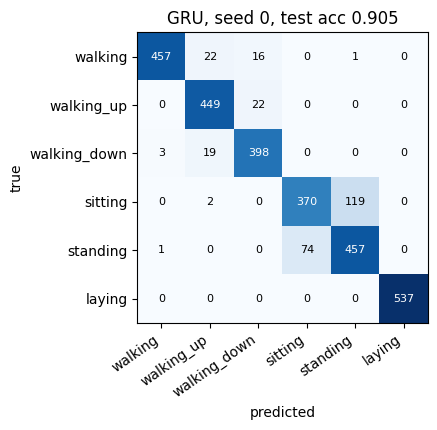

In [18]:
# Confusion matrix of the best HAR model (highest test accuracy over all 9 runs)
best = h.loc[h.test_acc.idxmax()]
pred = np.load(f"preds/har_main_{best.model}_{int(best.seed)}.npy")
yte_np = make_har(0)['yte'].numpy()                    # the test set does not depend on the seed
cm = confusion_matrix(yte_np, pred, labels=range(6))
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(cm, cmap='Blues')
for i in range(6):
    for j in range(6):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=8)
ax.set_xticks(range(6)); ax.set_xticklabels(CLASSES, rotation=35, ha='right')
ax.set_yticks(range(6)); ax.set_yticklabels(CLASSES)
ax.set_xlabel('predicted'); ax.set_ylabel('true')
ax.set_title(f'{best.model}, seed {int(best.seed)}, test acc {best.test_acc:.3f}')
plt.tight_layout(); plt.savefig('figures/har_confusion.png', dpi=150); plt.show()

**For the report:** Table (mean +- std, parameters, seconds/epoch) and the confusion-matrix figure. Look at which classes get confused (typically sitting vs standing, and the three walking classes) and quote the numbers from your table when you discuss RNN vs LSTM vs GRU.

## Task 4 - Adding problem
T in {50, 100, 200, 400}; RNN, LSTM, GRU; 3 seeds each. Data: 10,000 train (seed 0), 1,000 validation (seed 1), 1,000 test (seed 2) for every T.
**Assumptions (state them in the report):** hidden size 64, Adam lr 1e-3, batch 64, 30 epochs, MSE loss, no gradient clipping, checkpoint with the best validation MSE; identical for all models and lengths.
A run is *solved* if test MSE < 0.05; the constant-prediction baseline is about 0.167.

In [28]:
EPOCHS_ADD, BS_ADD, LR_ADD, HID_ADD = 30, 64, 1e-3, 64
SOLVED_THR, BASELINE = 0.05, 0.167
os.makedirs('curves', exist_ok=True)

_add_cache = {}
def add_data(T):
    # (Xtr, ytr, Xva, yva, Xte, yte) on DEVICE; same data for every model seed
    if T not in _add_cache:
        out = []
        for n, s in ((10000, 0), (1000, 1), (1000, 2)):
            x, y = make_adding(n, T, s)                      # x: (n, T, 2), y: (n,)
            out += [torch.tensor(x), torch.tensor(y)]
        _add_cache[T] = [t.to(DEVICE) for t in out]
    return _add_cache[T]

def eval_mse(model, X, y, bs=500):
    model.eval(); tot = 0.0
    with torch.no_grad():
        for i in range(0, len(X), bs):
            tot += ((model(X[i:i + bs]).squeeze(-1) - y[i:i + bs]) ** 2).sum().item()
    return tot / len(X)

def train_adding(kind, T, seed, hidden=HID_ADD, epochs=EPOCHS_ADD, bs=BS_ADD, lr=LR_ADD,
                 clip=None, forget_bias=None):
    # forget_bias (LSTM only): effective forget-gate bias at init (0 or 1) - used later for task 5(c)
    set_seed(seed)
    Xtr, ytr, Xva, yva, Xte, yte = add_data(T)
    model = SeqClassifier(kind, 2, hidden, 1).to(DEVICE)    # d_in = 2 channels, 1 regression output
    if forget_bias is not None:
        assert kind == 'LSTM'
        with torch.no_grad():                               # nn.LSTM bias layout: [input, forget, cell, output]
            model.rnn.bias_ih_l0[hidden:2 * hidden].fill_(forget_bias)
            model.rnn.bias_hh_l0[hidden:2 * hidden].zero_()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_va, best_state, times, hist = float('inf'), None, [], []
    for ep in range(epochs):
        model.train(); t0 = time.time()
        perm = torch.randperm(len(Xtr), device=DEVICE); run = 0.0
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            loss = F.mse_loss(model(Xtr[idx]).squeeze(-1), ytr[idx])
            opt.zero_grad(); loss.backward()
            if clip: nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step(); run += loss.item() * len(idx)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        times.append(time.time() - t0)
        va = eval_mse(model, Xva, yva)
        hist.append((run / len(Xtr), va))
        if va < best_va:
            best_va = va; best_state = {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return dict(test_mse=eval_mse(model, Xte, yte), best_val_mse=best_va,
                params=sum(p.numel() for p in model.parameters()),
                sec_per_epoch=float(np.mean(times)), hist=np.array(hist), model=model)

In [20]:
# Smoke test (NOT logged): 2 epochs at T=50 to catch bugs before the 36 real runs
r = train_adding('LSTM', 50, 0, epochs=2)
print('smoke test  test_mse %.4f  params %d  %.2fs/epoch   (baseline ~0.167)' % (r['test_mse'], r['params'], r['sec_per_epoch']))

smoke test  test_mse 0.1750  params 17473  0.62s/epoch   (baseline ~0.167)


In [21]:
# Main experiment: 4 lengths x 3 models x 3 seeds = 36 runs (resumable; learning curves saved to curves/)
for T in [50, 100, 200, 400]:
    for kind in ['RNN', 'LSTM', 'GRU']:
        for seed in SEEDS:
            if already_done(problem='P1', model=kind, seed=seed, seq_len=T, notes='adding_main'):
                continue
            r = train_adding(kind, T, seed)
            np.save(f'curves/add_{kind}_T{T}_s{seed}.npy', r['hist'])
            log_result(problem='P1', model=kind, seed=seed, seq_len=T, test_mse=round(r['test_mse'], 5),
                       params=r['params'], sec_per_epoch=round(r['sec_per_epoch'], 3), notes='adding_main')
            print(f"T={T:3d} {kind:5s} seed {seed}: test MSE {r['test_mse']:.4f}  "
                  f"{'SOLVED' if r['test_mse'] < SOLVED_THR else 'not solved'}  ({r['sec_per_epoch']:.2f}s/epoch)")

T= 50 RNN   seed 0: test MSE 0.1323  not solved  (0.35s/epoch)
T= 50 RNN   seed 1: test MSE 0.1608  not solved  (0.33s/epoch)
T= 50 RNN   seed 2: test MSE 0.1723  not solved  (0.32s/epoch)
T= 50 LSTM  seed 0: test MSE 0.0010  SOLVED  (0.36s/epoch)
T= 50 LSTM  seed 1: test MSE 0.0005  SOLVED  (0.36s/epoch)
T= 50 LSTM  seed 2: test MSE 0.0005  SOLVED  (0.36s/epoch)
T= 50 GRU   seed 0: test MSE 0.0003  SOLVED  (0.32s/epoch)
T= 50 GRU   seed 1: test MSE 0.0002  SOLVED  (0.34s/epoch)
T= 50 GRU   seed 2: test MSE 0.0002  SOLVED  (0.34s/epoch)
T=100 RNN   seed 0: test MSE 0.1706  not solved  (0.32s/epoch)
T=100 RNN   seed 1: test MSE 0.1692  not solved  (0.32s/epoch)
T=100 RNN   seed 2: test MSE 0.1702  not solved  (0.31s/epoch)
T=100 LSTM  seed 0: test MSE 0.0062  SOLVED  (0.36s/epoch)
T=100 LSTM  seed 1: test MSE 0.1694  not solved  (0.36s/epoch)
T=100 LSTM  seed 2: test MSE 0.0038  SOLVED  (0.36s/epoch)
T=100 GRU   seed 0: test MSE 0.0004  SOLVED  (0.34s/epoch)
T=100 GRU   seed 1: test MSE

In [22]:
# Table 4 (test MSE mean +- std) and Table 5 (solved runs)
df = pd.read_csv(RESULTS_PATH)
a = df[(df.problem == 'P1') & (df.notes == 'adding_main')].copy()
a['test_mse'] = a.test_mse.astype(float); a['seq_len'] = a.seq_len.astype(int)
Ts, models = [50, 100, 200, 400], ['RNN', 'LSTM', 'GRU']
t4 = pd.DataFrame({f'T={T}': {m: '{:.4f} +- {:.4f}'.format(g.mean(), g.std(ddof=1))
                              for m, g in a[a.seq_len == T].groupby('model').test_mse} for T in Ts}).loc[models]
t4.loc['baseline (predict 1.0)'] = ['~0.167'] * 4
print('Table 4 - test MSE (mean +- std over 3 seeds)'); print(t4.to_string()); print()
t5 = pd.DataFrame({f'T={T}': {m: f'{int((g < SOLVED_THR).sum())}/{len(g)}'
                              for m, g in a[a.seq_len == T].groupby('model').test_mse} for T in Ts}).loc[models]
print(f'Table 5 - solved runs (test MSE < {SOLVED_THR})'); print(t5.to_string())

Table 4 - test MSE (mean +- std over 3 seeds)
                                    T=50             T=100             T=200             T=400
RNN                     0.1551 +- 0.0206  0.1700 +- 0.0007  0.1687 +- 0.0004  0.1539 +- 0.0005
LSTM                    0.0007 +- 0.0003  0.0598 +- 0.0949  0.1685 +- 0.0003  0.1536 +- 0.0002
GRU                     0.0002 +- 0.0000  0.0004 +- 0.0001  0.0005 +- 0.0001  0.0014 +- 0.0004
baseline (predict 1.0)            ~0.167            ~0.167            ~0.167            ~0.167

Table 5 - solved runs (test MSE < 0.05)
     T=50 T=100 T=200 T=400
RNN   0/3   0/3   0/3   0/3
LSTM  3/3   2/3   0/3   0/3
GRU   3/3   3/3   3/3   3/3


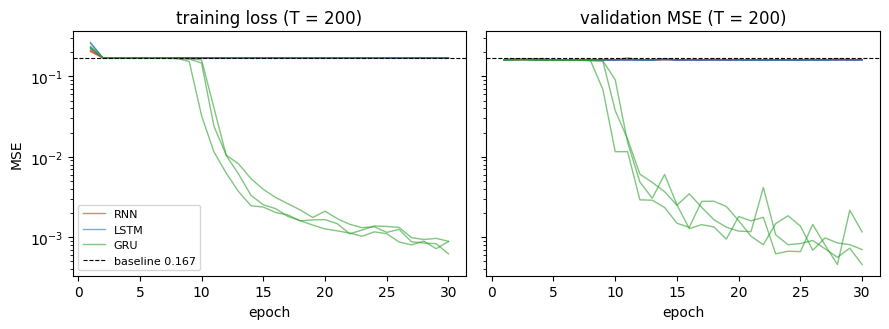

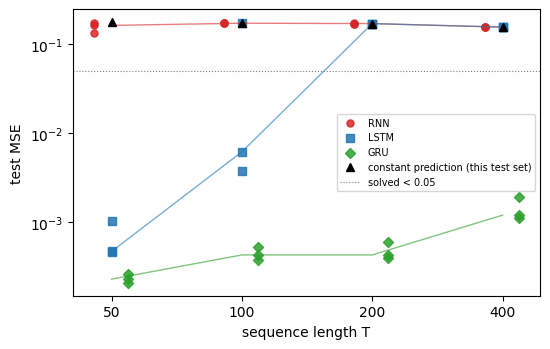

In [26]:
# Figure 3: learning curves at T = 200 (per-epoch training loss and validation MSE, 3 seeds per model)
col = {'RNN': 'tab:red', 'LSTM': 'tab:blue', 'GRU': 'tab:green'}
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for m in models:
    for s in SEEDS:
        h = np.load(f'curves/add_{m}_T200_s{s}.npy')              # (epochs, 2): train loss, val MSE
        ep = np.arange(1, len(h) + 1)
        ax[0].plot(ep, h[:, 0], color=col[m], alpha=0.6, lw=1, label=m if s == SEEDS[0] else None)
        ax[1].plot(ep, h[:, 1], color=col[m], alpha=0.6, lw=1, label=m if s == SEEDS[0] else None)
for a_, t in zip(ax, ['training loss', 'validation MSE']):
    a_.axhline(BASELINE, color='k', ls='--', lw=0.8, label='baseline 0.167')
    a_.set_yscale('log'); a_.set_xlabel('epoch'); a_.set_title(t + ' (T = 200)')
ax[0].set_ylabel('MSE'); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/adding_curves_T200.png', dpi=150); plt.show()

# Figure 4: test MSE against T (one marker per seed; no mean lines)
ref = {T: float(np.mean((add_data(T)[5].cpu().numpy() - 1.0) ** 2)) for T in Ts}   # constant-prediction MSE per test set
mk = {'RNN': 'o', 'LSTM': 's', 'GRU': 'D'}
plt.figure(figsize=(5.6, 3.6))
for i, m in enumerate(models):
    g = a[a.model == m]
    plt.scatter(g.seq_len * (1 + 0.09 * (i - 1)), g.test_mse, color=col[m], marker=mk[m], s=26, alpha=0.85, label=m)
    plt.plot(Ts, g.groupby('seq_len').test_mse.median().loc[Ts], color=col[m], lw=1, alpha=0.6)
plt.plot(Ts, [ref[T] for T in Ts], 'k^', ms=6, label='constant prediction (this test set)')
plt.axhline(SOLVED_THR, color='gray', ls=':', lw=0.8, label='solved < 0.05')
plt.xscale('log'); plt.yscale('log'); plt.xticks(Ts, Ts); plt.minorticks_off()
plt.xlabel('sequence length T'); plt.ylabel('test MSE'); plt.legend(fontsize=7)
plt.tight_layout(); plt.savefig('figures/adding_mse_vs_T.png', dpi=150); plt.show()

**For the report:** Table 4, Table 5, Figure 3 and Figure 4, plus the stated assumptions. Describe only what the tables show: which models solve which lengths, where each fails, and whether the plain RNN stays near the 0.167 baseline. If LSTM/GRU are unsolved at T = 200-400, say so and discuss epochs/clipping as a possible cause without claiming it was tested.

## Task 5 - Gradients, ablations and analysis
**Before running 5(a): re-run the cell that defines `train_adding`** (it now also returns the trained model). You do NOT need to re-run the 36-run loop.

### 5(a) Gradient norm ||dL/dh_t|| against t at T = 100, before and after training
Library layers do not expose per-step gradients (cuDNN), so I build a from-scratch twin (`MySeq` cells, verified equal to the library layers in task 2), copy the weights in, run the unrolled loop, call `retain_grad()` on every h_t and take the loss on the last step only.

In [31]:
print('model' in train_adding('GRU', 50, 0, epochs=1))

True


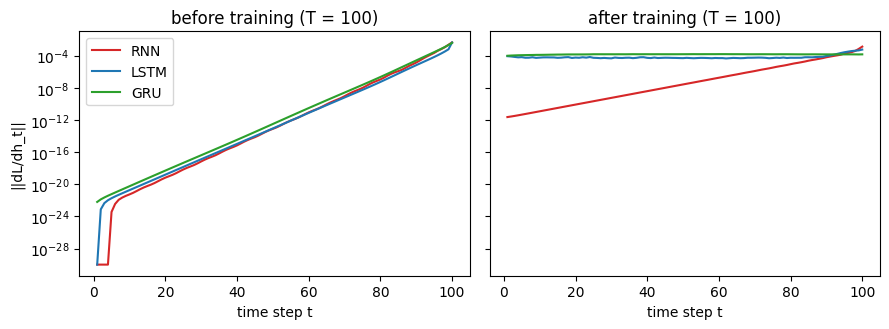

RNN   before |g(t=1)| = 0.000e+00   |g(t=T)| = 4.251e-03   ratio = 0.000e+00
RNN   after  |g(t=1)| = 2.233e-12   |g(t=T)| = 1.281e-03   ratio = 1.743e-09
LSTM  before |g(t=1)| = 0.000e+00   |g(t=T)| = 4.225e-03   ratio = 0.000e+00
LSTM  after  |g(t=1)| = 8.303e-05   |g(t=T)| = 5.488e-04   ratio = 1.513e-01
GRU   before |g(t=1)| = 6.230e-23   |g(t=T)| = 3.714e-03   ratio = 1.677e-20
GRU   after  |g(t=1)| = 9.368e-05   |g(t=T)| = 1.402e-04   ratio = 6.682e-01


In [32]:
def grad_norms(kind, lib_model, T=100, n=256):
    # returns ||dL/h_t|| for t = 1..T, averaged over n sequences; shapes: x (n, T, 2), h_t (n, h)
    Cell = KINDS[kind][0]
    twin = MySeq(Cell(2, HID_ADD, two_bias=True)).to(DEVICE)
    copy_weights(twin, lib_model.rnn)
    Xtr, ytr = add_data(T)[:2]
    x, y = Xtr[:n], ytr[:n]
    cell = twin.cell; state = cell.init_state(n, DEVICE); hs = []
    for t in range(T):
        o, state = cell(x[:, t], state)           # o is h_t (same tensor that feeds step t+1)
        o.retain_grad(); hs.append(o)
    loss = F.mse_loss(lib_model.head(hs[-1]).squeeze(-1), y)
    loss.backward()
    return np.array([h.grad.norm(dim=-1).mean().item() for h in hs])   # (T,)

T_G = 100
G = {}
for kind in ['RNN', 'LSTM', 'GRU']:
    set_seed(0)
    fresh = SeqClassifier(kind, 2, HID_ADD, 1).to(DEVICE)               # before training
    G[(kind, 'before')] = grad_norms(kind, fresh, T_G)
    trained = train_adding(kind, T_G, 0)['model']                        # after training (seed 0, 30 epochs)
    G[(kind, 'after')] = grad_norms(kind, trained, T_G)

col = {'RNN': 'tab:red', 'LSTM': 'tab:blue', 'GRU': 'tab:green'}
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
t_ax = np.arange(1, T_G + 1)
for a_, when in zip(ax, ['before', 'after']):
    for kind in col:
        a_.plot(t_ax, np.maximum(G[(kind, when)], 1e-30), color=col[kind], label=kind)
    a_.set_yscale('log'); a_.set_xlabel('time step t'); a_.set_title(f'{when} training (T = 100)')
ax[0].set_ylabel('||dL/dh_t||'); ax[0].legend()
plt.tight_layout(); plt.savefig('figures/grad_norm_T100.png', dpi=150); plt.show()
# numbers for the write-up: gradient at t=1 relative to t=T
for k in ['RNN', 'LSTM', 'GRU']:
    for w in ['before', 'after']:
        g = G[(k, w)]; print(f'{k:5s} {w:6s} |g(t=1)| = {g[0]:.3e}   |g(t=T)| = {g[-1]:.3e}   ratio = {g[0] / g[-1]:.3e}')

### 5(b) Hidden-size sweep {16, 32, 64, 128} for LSTM and GRU on HAR
Same budget as task 3 (Adam 1e-3, batch 64, 30 epochs), 3 seeds. Hidden size 64 is reused from the task 3 runs (`har_main`), not retrained.

In [33]:
H_LIST = [16, 32, 64, 128]
for kind in ['LSTM', 'GRU']:
    for H in H_LIST:
        if H == 64: continue                                  # already in results.csv as har_main
        for seed in SEEDS:
            notes = f'har_h{H}'
            if already_done(problem='P1', model=kind, seed=seed, seq_len=128, notes=notes): continue
            r = train_har(kind, seed, hidden=H)
            log_result(problem='P1', model=kind, seed=seed, seq_len=128, test_acc=round(r['test_acc'], 4),
                       macro_f1=round(r['macro_f1'], 4), params=r['params'],
                       sec_per_epoch=round(r['sec_per_epoch'], 3), notes=notes)
            print(f'{kind:5s} H={H:3d} seed {seed}: acc {r["test_acc"]:.4f}  params {r["params"]}')

LSTM  H= 16 seed 0: acc 0.8639  params 1830
LSTM  H= 16 seed 1: acc 0.7727  params 1830
LSTM  H= 16 seed 2: acc 0.8290  params 1830
LSTM  H= 32 seed 0: acc 0.8894  params 5702
LSTM  H= 32 seed 1: acc 0.8867  params 5702
LSTM  H= 32 seed 2: acc 0.8809  params 5702
LSTM  H=128 seed 0: acc 0.9097  params 71942
LSTM  H=128 seed 1: acc 0.8860  params 71942
LSTM  H=128 seed 2: acc 0.9135  params 71942
GRU   H= 16 seed 0: acc 0.8873  params 1398
GRU   H= 16 seed 1: acc 0.8761  params 1398
GRU   H= 16 seed 2: acc 0.9013  params 1398
GRU   H= 32 seed 0: acc 0.8914  params 4326
GRU   H= 32 seed 1: acc 0.8700  params 4326
GRU   H= 32 seed 2: acc 0.8765  params 4326
GRU   H=128 seed 0: acc 0.9169  params 54150
GRU   H=128 seed 1: acc 0.8911  params 54150
GRU   H=128 seed 2: acc 0.9053  params 54150


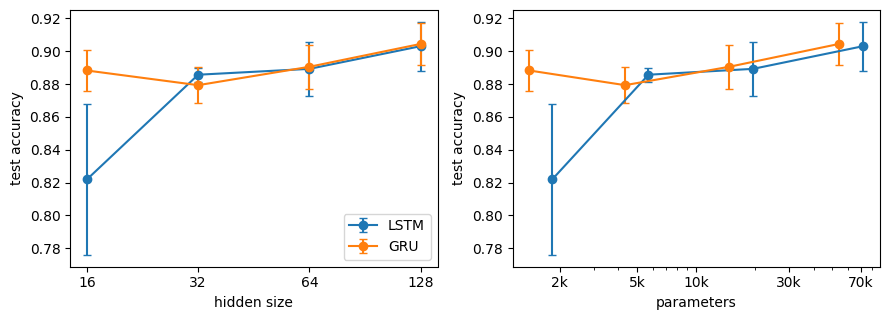

model  hidden test acc (mean +- std)  params sec/epoch
 LSTM      16       0.8219 +- 0.0460    1830      0.21
 LSTM      32       0.8857 +- 0.0043    5702      0.21
 LSTM      64       0.8892 +- 0.0164   19590      0.23
 LSTM     128       0.9031 +- 0.0149   71942      0.35
  GRU      16       0.8882 +- 0.0126    1398      0.20
  GRU      32       0.8793 +- 0.0110    4326      0.21
  GRU      64       0.8905 +- 0.0133   14790      0.20
  GRU     128       0.9044 +- 0.0129   54150      0.21


In [35]:
df = pd.read_csv(RESULTS_PATH); df = df[df.problem == 'P1']
def hrows(kind, H): return df[(df.model == kind) & (df.notes == ('har_main' if H == 64 else f'har_h{H}'))]
tab = []
fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
for kind in ['LSTM', 'GRU']:
    m = [hrows(kind, H).test_acc.mean() for H in H_LIST]; s = [hrows(kind, H).test_acc.std(ddof=1) for H in H_LIST]
    p = [int(hrows(kind, H).params.iloc[0]) for H in H_LIST]
    ax[0].errorbar(H_LIST, m, yerr=s, marker='o', capsize=3, label=kind)
    ax[1].errorbar(p, m, yerr=s, marker='o', capsize=3, label=kind)
    for H, mm, ss, pp in zip(H_LIST, m, s, p):
        tab.append((kind, H, f'{mm:.4f} +- {ss:.4f}', pp, f'{hrows(kind, H).sec_per_epoch.mean():.2f}'))
ax[0].set_xscale('log', base=2); ax[0].set_xticks(H_LIST); ax[0].set_xticklabels(H_LIST)
ax[0].set_xlabel('hidden size'); ax[0].set_ylabel('test accuracy'); ax[0].legend()
ax[1].set_xscale('log'); ax[1].set_xlabel('parameters'); ax[1].set_ylabel('test accuracy')
ax[1].set_xticks([2e3, 5e3, 1e4, 3e4, 7e4]); ax[1].set_xticklabels(['2k', '5k', '10k', '30k', '70k'])
plt.tight_layout(); plt.savefig('figures/har_hidden_sweep.png', dpi=150); plt.show()
print(pd.DataFrame(tab, columns=['model', 'hidden', 'test acc (mean +- std)', 'params', 'sec/epoch']).to_string(index=False))

### 5(c) Your ablation (last digit 7, odd): LSTM forget-gate bias initialised to 0 versus 1, T = 200
Effective forget bias set exactly to 0 or 1 at initialisation (`bias_ih` forget slice = b, `bias_hh` forget slice = 0), all other settings as in task 4, 3 seeds each. The default-initialisation LSTM from task 4 (0/3 solved at T = 200) is the reference, not a third arm of the ablation.

In [36]:
for b in [0.0, 1.0]:
    for seed in SEEDS:
        notes = f'fgate_b{int(b)}'
        if already_done(problem='P1', model='LSTM', seed=seed, seq_len=200, notes=notes): continue
        r = train_adding('LSTM', 200, seed, forget_bias=b)
        np.save(f'curves/fg_b{int(b)}_s{seed}.npy', r['hist'])
        log_result(problem='P1', model='LSTM', seed=seed, seq_len=200, test_mse=round(r['test_mse'], 5),
                   params=r['params'], sec_per_epoch=round(r['sec_per_epoch'], 3), notes=notes)
        print(f'forget bias {b:.0f} seed {seed}: test MSE {r["test_mse"]:.4f}  '
              f'{"SOLVED" if r["test_mse"] < SOLVED_THR else "not solved"}')

forget bias 0 seed 0: test MSE 0.1685  not solved
forget bias 0 seed 1: test MSE 0.1682  not solved
forget bias 0 seed 2: test MSE 0.1687  not solved
forget bias 1 seed 0: test MSE 0.1686  not solved
forget bias 1 seed 1: test MSE 0.1685  not solved
forget bias 1 seed 2: test MSE 0.1693  not solved


              setting      test MSE per seed solved
        forget bias 0 0.1685, 0.1682, 0.1687    0/3
        forget bias 1 0.1686, 0.1685, 0.1693    0/3
default init (task 4) 0.1685, 0.1682, 0.1688    0/3


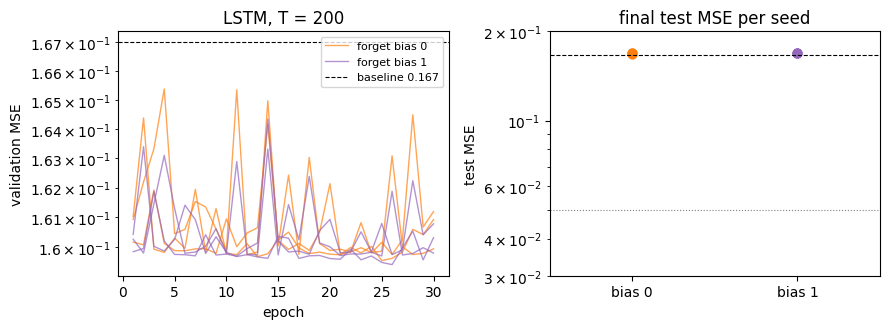

In [38]:
df = pd.read_csv(RESULTS_PATH); df = df[df.problem == 'P1']
rows_ = []
for b in [0, 1]:
    g = df[df.notes == f'fgate_b{b}'].test_mse.astype(float)
    rows_.append((f'forget bias {b}', ', '.join(f'{v:.4f}' for v in g), f'{int((g < SOLVED_THR).sum())}/{len(g)}'))
ref = df[(df.notes == 'adding_main') & (df.model == 'LSTM') & (df.seq_len == 200)].test_mse.astype(float)
rows_.append(('default init (task 4)', ', '.join(f'{v:.4f}' for v in ref), f'{int((ref < SOLVED_THR).sum())}/{len(ref)}'))
print(pd.DataFrame(rows_, columns=['setting', 'test MSE per seed', 'solved']).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for b, c in ((0, 'tab:orange'), (1, 'tab:purple')):
    for s in SEEDS:
        h = np.load(f'curves/fg_b{b}_s{s}.npy')
        ax[0].plot(np.arange(1, len(h) + 1), h[:, 1], color=c, alpha=0.7, lw=1, label=f'forget bias {b}' if s == SEEDS[0] else None)
ax[0].axhline(BASELINE, color='k', ls='--', lw=0.8, label='baseline 0.167')
ax[0].set_yscale('log'); ax[0].set_xlabel('epoch'); ax[0].set_ylabel('validation MSE'); ax[0].set_title('LSTM, T = 200'); ax[0].legend(fontsize=8)
for i, (b, c) in enumerate(((0, 'tab:orange'), (1, 'tab:purple'))):
    v = df[df.notes == f'fgate_b{b}'].test_mse.astype(float).values
    ax[1].scatter([i] * len(v), v, color=c, s=40)
ax[1].axhline(BASELINE, color='k', ls='--', lw=0.8); ax[1].axhline(SOLVED_THR, color='gray', ls=':', lw=0.8)
ax[1].set_yscale('log'); ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(['bias 0', 'bias 1']); ax[1].set_xlim(-0.5, 1.5)
ax[1].set_ylim(0.03, 0.2)
ax[1].set_ylabel('test MSE'); ax[1].set_title('final test MSE per seed')
plt.tight_layout(); plt.savefig('figures/forget_bias_ablation.png', dpi=150); plt.show()